# Growth patterns and recipient characteristics

What changes accompany funding growth each year and across 2020-2025?

**Scope:** All recipients in the shared legal-form cohort, not only the top 1%. Annual comparisons use recipient/consecutive-year pairs; whole-period comparisons use one recipient with valid 2020 and 2025 endpoints. Each measure reports its applicable sample.

This notebook compares annual funding changes and fixed 2020-2025 growth, then examines the accompanying changes in requests and funding per request. This is a descriptive analysis, not a causal model or a test of baseline predictors. Coverage is reported first because not every recorded recipient has a comparable growth history.

The [Methodology](../METHODOLOGY.md) documents definitions and correction policies. The [Project overview](../README.md) describes the notebook sequence and dataset rebuild process.

## Analysis configuration

The setup defines libraries, project paths and the shared theme. The notebook is designed for sequential execution in a fresh kernel.

In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Locate the checkout from the project folder or a notebook subfolder.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "analysis_helpers.py").is_file()
     and (p / "config" / "sources.yaml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project folder.")
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from chart_style import apply_chart_style, colors_from_style, growth_cmap_from_style, load_chart_style

chart_style = load_chart_style(PROJECT_ROOT)
apply_chart_style(chart_style)
CHART_COLORS = colors_from_style(chart_style)
GROWTH_CMAP = growth_cmap_from_style(chart_style)
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

## The shared comparison population

The comparison population contains 2020-2025 recipient-year records whose legal form is observed in 2025. Historical recipients do not themselves need to appear in 2025. The exclusion report documents omitted records; dataset absence does not prove legal ineligibility.

In [ ]:
vmi = pd.read_csv(PROCESSED_DIR / "recipient_analysis.csv", low_memory=False, dtype={"recipient_code": "string"})

vmi["tax_year"] = pd.to_numeric(vmi["tax_year"], errors="coerce")
vmi["recipient_code"] = vmi["recipient_code"].astype("string").str.strip()
vmi["requests"] = pd.to_numeric(vmi["requests"], errors="coerce")
vmi["calculated_pmd_eur"] = pd.to_numeric(vmi["calculated_pmd_eur"], errors="coerce")
vmi["organization_age"] = pd.to_numeric(vmi["organization_age"], errors="coerce")

vmi["legal_form_clean"] = vmi["legal_form"].fillna("Unknown").str.strip()
vmi["organization_age_group"] = (
    vmi["organization_age_group"]
    .astype("string")
    .fillna("Unknown")
    .replace({
        "10-Jun": "6-10",
        "15-Nov": "11-15",
        "nan": "Unknown",
        "NaN": "Unknown",
        "<NA>": "Unknown",
    })
)

from cohort import START_YEAR, END_YEAR, LEGAL_FORM_REFERENCE_YEAR, filter_recipient_cohort, show_cohort_report
vmi_filtered, cohort_yearly_report, excluded_legal_forms, legal_form_changes = filter_recipient_cohort(vmi)
show_cohort_report(cohort_yearly_report, excluded_legal_forms, legal_form_changes)


print(f"Rows before legal-form filter: {len(vmi):,}")
print(f"Rows after legal-form filter: {len(vmi_filtered):,}")
print(f"Unique recipients after filter: {vmi_filtered['recipient_code'].nunique():,}")

vmi_filtered.head()

Legal forms observed in 2025; analysis years 2020-2025.
Filtering applies to recipient-year legal forms, not survival of each recipient in 2025.
Yearly inclusion and exclusion totals (amounts sum known values):


,tax_year,all_recipients,all_rows,all_pmd_eur,included_recipients,included_rows,included_pmd_eur,excluded_recipients,excluded_rows,excluded_pmd_eur,excluded_pmd_share,missing_amount_rows
0,2020,23240,23240,"21,654,753.19",16748,16748,"17,253,053.18",6492,6492,"4,401,700.01",20.33%,0
1,2021,22798,22798,"27,843,175.86",16325,16325,"22,940,811.40",6473,6473,"4,902,364.46",17.61%,0
2,2022,22147,22147,"29,202,852.20",15744,15744,"24,254,670.09",6403,6403,"4,948,182.11",16.94%,0
3,2023,22555,22555,"33,985,135.12",16252,16252,"28,543,797.48",6303,6303,"5,441,337.64",16.01%,0
4,2024,14511,14511,"36,904,168.23",14503,14503,"36,895,489.41",8,8,"8,678.82",0.02%,0
5,2025,15483,15483,"40,124,624.74",15483,15483,"40,124,624.74",0,0,0.00,0.00%,0


Excluded legal forms; absence is not evidence of legal ineligibility:


,legal_form_clean,exclusion_reason,recipients,rows,pmd_eur
0,Bendrija,Not observed in reference year,4048,13548,"4,267,247.25"
1,Biudžetinė įstaiga,Not observed in reference year,2436,8977,"13,942,264.28"
2,Mažoji bendrija,Not observed in reference year,15,54,"16,006.40"
3,"Prekybos, pramonės ir amatų rūmai",Not observed in reference year,4,13,"6,139.28"
4,Regiono plėtros taryba,Not observed in reference year,1,3,353.56
5,Sodininkų bendrija,Not observed in reference year,803,2869,"1,330,995.52"
6,Uždaroji akcinė bendrovė,Not observed in reference year,26,87,"83,911.66"
7,Šeimyna,Not observed in reference year,45,128,"55,345.09"


Recipients with multiple recorded legal forms: 0
The full legal_form_changes table retains every affected recipient-year; preview:


,recipient_code,recipient_name,tax_year,legal_form_clean,included_in_cohort


A recipient can appear in both inclusion groups within a year if its source records have different forms.
Rows before legal-form filter: 120,734
Rows after legal-form filter: 95,055
Unique recipients after filter: 23,401


## Annual and fixed-period growth calculations

Annual growth requires consecutive observations. Whole-period growth compares 2020 with 2025, requiring both endpoints and positive starting funding; a zero ending gives -100%. Natural-log growth requires both amounts to be positive. Missing observations are never converted to zero. Mean annual log growth summarizes available annual changes, not volatility.

In [3]:
from growth_analysis import build_growth_analysis, growth_table as make_growth_table, render_growth_heatmap, render_short_histories
from cohort import START_YEAR, END_YEAR

recipient_year_amounts, period_summary = build_growth_analysis(
    vmi_filtered, start=START_YEAR, end=END_YEAR
)
growth_summary = recipient_year_amounts.groupby("recipient_code", as_index=False).agg(
    total_pmd_eur=("amount", lambda s: s.sum(min_count=1)),
    total_requests=("requests", lambda s: s.sum(min_count=1)),
    average_log_growth=("yearly_log_growth", "mean"),
    positive_growth_years=("yearly_growth_pct", lambda s: (s > 0).sum()),
    negative_growth_years=("yearly_growth_pct", lambda s: (s < 0).sum()),
    years_with_growth_data=("yearly_growth_pct", "count"),
)
growth_summary = growth_summary.merge(period_summary, on="recipient_code", validate="one_to_one")
# Existing downstream fields now refer to the same fixed endpoints.
growth_summary["first_year"] = START_YEAR
growth_summary["last_year"] = END_YEAR
growth_summary["first_year_amount"] = growth_summary["baseline_amount"]
growth_summary["last_year_amount"] = growth_summary["endpoint_amount"]
growth_summary["whole_period_growth_pct"] = growth_summary["fixed_period_growth_pct"]
growth_summary["whole_period_log_growth"] = growth_summary["fixed_period_log_growth"]
growth_summary["average_amount_per_request"] = (
    growth_summary["total_pmd_eur"] / growth_summary["total_requests"].where(growth_summary["total_requests"] > 0)
)
growth_summary.head()

,recipient_code,total_pmd_eur,total_requests,average_log_growth,positive_growth_years,negative_growth_years,years_with_growth_data,recipient_name,observed_years,first_observed_year,...,fixed_period_log_growth,fixed_annualized_log_growth,fixed_period_status,first_year,last_year,first_year_amount,last_year_amount,whole_period_growth_pct,whole_period_log_growth,average_amount_per_request
0,110055327,1259.13,12,0.339946,2,1,3,Lietuvos žemės ūkio bendrovių asociacija,4,2020,...,NaN,NaN,Missing endpoint,2020,2025,187.28,NaN,NaN,NaN,104.927500
1,110057335,8827.97,133,0.260612,3,2,5,Viešoji įstaiga Lietuvos žemės ūkio konsultavi...,6,2020,...,1.303058,0.260612,Available,2020,2025,536.49,1974.57,2.680535,1.303058,66.375714
2,110058960,1410.55,24,0.005538,3,2,5,"Viešoji įstaiga Studija ""PRO PATRIA""",6,2020,...,0.027692,0.005538,Available,2020,2025,366.11,376.39,0.028079,0.027692,58.772917
3,110059496,19173.06,97,-0.336314,3,2,5,"Viešoji įstaiga ""Lietuvos laisvosios rinkos in...",6,2020,...,-1.681569,-0.336314,Available,2020,2025,3061.61,569.71,-0.813918,-1.681569,197.660412
4,110061038,229.67,13,1.192225,1,2,3,Asociacija LATGA,4,2022,...,NaN,NaN,Missing endpoint,2020,2025,NaN,218.46,NaN,NaN,17.666923


## Comparable observation histories

These counts cover the full filtered population and separate available fixed-period comparisons from insufficient histories or baselines. They establish the population before the recipient rankings and charts.

In [4]:
period_summary.groupby("fixed_period_status").agg(recipients=("recipient_code", "nunique"))

,recipients
fixed_period_status,
Available,10381
Invalid or zero baseline,27
Missing endpoint,12993


## The fixed-endpoint recipient table

The fixed-endpoint table contains one row per recipient with available fixed-period percentage growth, enriched with their latest recorded characteristics. Age groups refer to 2025 for this sample, not baseline age. Municipality and legal form are descriptive attributes, and full-period requests are measured during the growth being described.

In [5]:
recipient_dimensions = (
    vmi_filtered
    .sort_values(["recipient_code", "tax_year"])
    .groupby("recipient_code", as_index=False)
    .agg(
        municipality=("recipient_municipality", "last"),
        legal_form_clean=("legal_form_clean", "last"),
        organization_age=("organization_age", "last"),
        age_reference_year=("tax_year", "last"),
        organization_age_group=("organization_age_group", "last")
    )
)

growth_driver_table = growth_summary.merge(
    recipient_dimensions,
    on="recipient_code",
    validate="one_to_one",
    how="left"
)

growth_driver_table = growth_driver_table.loc[
    growth_driver_table["fixed_period_status"].eq("Available")
].copy()

growth_driver_table = growth_driver_table.sort_values(
    "whole_period_log_growth",
    ascending=False
)

growth_driver_table.head(20)

,recipient_code,total_pmd_eur,total_requests,average_log_growth,positive_growth_years,negative_growth_years,years_with_growth_data,recipient_name,observed_years,first_observed_year,...,first_year_amount,last_year_amount,whole_period_growth_pct,whole_period_log_growth,average_amount_per_request,municipality,legal_form_clean,organization_age,age_reference_year,organization_age_group
16492,304772988,643.93,15,8.374477,1,0,1,Asociacija Lietuvos suaugusių alkoholikų vaikų...,4,2020,...,0.01,434.72,43471.000000,10.679872,42.928667,Vilniaus m. sav.,Asociacija,7.0,2025,6-10
4013,191378498,4392.60,76,1.930987,5,0,5,Kauno miesto musulmonų religinė bendruomenė,6,2020,...,0.13,2027.81,15597.538462,9.654933,57.797368,Kauno m. sav.,Tradicinė religinė bendruomenė ar bendrija,29.0,2025,26-30
12992,303122222,375.13,10,1.875010,4,1,5,Lengvosios atletikos asociacija,6,2020,...,0.02,235.81,11789.500000,9.375049,37.513000,Vilniaus m. sav.,Asociacija,12.0,2025,11-15
6725,293339790,791.07,22,-0.771389,0,2,2,"Krikščionių misija ""Aušra""",4,2020,...,0.03,250.11,8336.000000,9.028459,35.957727,Marijampolės sav.,Asociacija,25.0,2025,21-25
5054,192104272,1173.14,30,1.681458,5,0,5,Lazdijų sentikių religinė bendruomenė,6,2020,...,0.13,582.35,4478.615385,8.407292,39.104667,Lazdijų r. sav.,Tradicinė religinė bendruomenė ar bendrija,22.0,2025,21-25
1386,155324180,823.97,45,1.630106,4,1,5,Geidžiūnų bendruomenė,6,2020,...,0.09,311.87,3464.222222,8.150532,18.310444,Biržų r. sav.,Asociacija,22.0,2025,21-25
6907,300024837,420.84,15,1.620517,3,2,5,"Labdaros ir paramos fondas ""VILTIES KALNAS""",6,2020,...,0.08,264.24,3302.000000,8.102586,28.056000,Šiaulių m. sav.,Labdaros ir paramos fondas,21.0,2025,21-25
8963,301534825,2867.66,50,1.596137,4,1,5,Lietuvių skalikų augintojų sąjunga,6,2020,...,0.50,1461.97,2922.940000,7.980687,57.353200,Kupiškio r. sav.,Asociacija,17.0,2025,16-20
12445,302937302,6672.18,114,0.938183,2,1,3,"Sporto klubas ""Šilalės lūšis""",5,2020,...,0.62,1718.62,2770.967742,7.927313,58.527895,Šilalės r. sav.,Asociacija,13.0,2025,11-15
6249,250129430,27164.58,868,1.564866,5,0,5,Lietuvos švietimo darbuotojų profesinės sąjung...,6,2020,...,5.07,12678.62,2499.714004,7.824332,31.295599,Vilniaus m. sav.,Profesinė sąjunga ar susivienijimas,24.0,2025,21-25


## Samples underlying log-growth statistics

Total recipients means the fixed-endpoint percentage-growth sample, not the full source population. Valid log-growth recipients additionally have finite log growth. Zero-ending recipients stay in percentage comparisons but not log means or medians. Other monetary and request summaries use their stated full-sample scope.

In [6]:
valid_log_growth = growth_driver_table.loc[
    np.isfinite(growth_driver_table["whole_period_log_growth"])
].copy()
total_recipients = growth_driver_table["recipient_code"].nunique()
valid_log_growth_recipients = valid_log_growth["recipient_code"].nunique()

summary_findings = pd.DataFrame({
    "metric": [
        "total_recipients",
        "valid_log_growth_recipients",
        "excluded_from_log_growth",
        "Median log growth 2020-2025",
        "Mean log growth 2020-2025",
        "Median first-year amount",
        "Median total requests",
        "Median average amount per request",
    ],
    "value": [
        total_recipients,
        valid_log_growth_recipients,
        total_recipients - valid_log_growth_recipients,
        valid_log_growth["whole_period_log_growth"].median(),
        valid_log_growth["whole_period_log_growth"].mean(),
        growth_driver_table["first_year_amount"].median(),
        growth_driver_table["total_requests"].median(),
        growth_driver_table["average_amount_per_request"].median(),
    ],
})
display(summary_findings)

,metric,value
0,total_recipients,10381.000000
1,valid_log_growth_recipients,10355.000000
2,excluded_from_log_growth,26.000000
3,Median log growth 2020-2025,0.480308
4,Mean log growth 2020-2025,0.488893
5,Median first-year amount,380.860000
6,Median total requests,57.000000
7,Median average amount per request,50.936393


## Annual and whole-period growth heatmap

This heatmap returns to the full filtered population where each comparison is available, not only the fixed-endpoint sample. Purple indicates decline, pink neutral, green growth and light grey unavailable comparisons. The first 30 rows are an ordered preview using the full color scale; the exported HTML contains all rows.

In [7]:
growth_table, recipient_labels = make_growth_table(recipient_year_amounts, period_summary, START_YEAR, END_YEAR)
render_growth_heatmap(growth_table, recipient_labels, GROWTH_CMAP, CHART_COLORS, output_path=PROJECT_ROOT / "outputs" / "heatmaps" / "07_percentage_growth.html", preview_rows=30)

tax_year,2021,2022,2023,2024,2025,Growth 2020-2025,Annualized 2020-2025
Recipient,,,,,,,
Asociacija Lietuvos suaugusių alkoholikų vaikų bendrija,"+433,400%",Unavailable,Unavailable,Unavailable,Unavailable,"+4,347,100%",+746.5%
Kauno miesto musulmonų religinė bendruomenė,+807.7%,"+22,739.8%",+256.6%,+17.9%,+79%,"+1,559,753.8%",+589.6%
Lengvosios atletikos asociacija,"+2,150%",+20%,"+17,813%",-57%,+467.1%,"+1,178,950%",+552.1%
"Krikščionių misija ""Aušra""",-100%,Unavailable,Unavailable,Unavailable,-53.8%,"+833,600%",+508.4%
Lazdijų sentikių religinė bendruomenė,"+46,623.1%",+0.1%,+203.2%,+54.6%,+104.4%,"+447,861.5%",+437.3%
Geidžiūnų bendruomenė,"+87,155.6%",-1.3%,+116%,+12.7%,+65.3%,"+346,422.2%",+410.4%
"Labdaros ir paramos fondas ""VILTIES KALNAS""","+47,162.5%",-94.9%,"+3,062.5%",-7.7%,+371.3%,"+330,200%",+405.6%
Lietuvių skalikų augintojų sąjunga,"+12,818%",-98.3%,"+12,972.9%",+757.6%,+21.9%,"+292,294%",+393.4%
"Sporto klubas ""Šilalės lūšis""",Unavailable,Unavailable,"+2,201.2%",+4.6%,-30.7%,"+277,096.8%",+388.2%


## Intervals containing missing years

These observations are separated by more than one year. Interval growth measures the whole observed gap and is deliberately excluded from annual growth. Missing years are not evidence of zero funding.

In [8]:
gap_review = recipient_year_amounts.loc[
    recipient_year_amounts["year_gap"] > 1,
    [
        "recipient_name",
        "previous_observed_year",
        "tax_year",
        "year_gap",
        "previous_year_amount",
        "amount",
        "interval_growth_pct",
    ],
].copy()

print(f"Comparisons spanning more than one year: {len(gap_review):,}")

display(
    gap_review.head(30).style.format(
        {
            "previous_observed_year": "{:.0f}",
            "tax_year": "{:.0f}",
            "year_gap": "{:.0f}",
            "previous_year_amount": "{:,.2f} €",
            "amount": "{:,.2f} €",
            "interval_growth_pct": "{:.1%}",
        },
        na_rep="No data",
    )
)

Comparisons spanning more than one year: 2,386


,recipient_name,previous_observed_year,tax_year,year_gap,previous_year_amount,amount,interval_growth_pct
44,"Viešoji įstaiga sanatorija ""Belorus""",2022,2024,2,40.97 €,46.74 €,14.1%
287,"Lietuvos nacionalinė vežėjų automobiliais asociacija ""LINAVA""",2022,2024,2,92.02 €,780.50 €,748.2%
299,"Viešoji įstaiga ""VILNIAUS ARKIVYSKUPIJOS EKONOMO TARNYBA""",2022,2024,2,249.31 €,36.03 €,-85.5%
321,LIETUVOS STATYBININKŲ ASOCIACIJA,2020,2022,2,71.97 €,96.65 €,34.3%
414,LIETUVOS KREPŠINIO LYGA (LKL),2021,2024,3,746.59 €,"3,059.40 €",309.8%
418,"Viešoji įstaiga ""A PROPOS"" STUDIJA",2022,2024,2,543.59 €,45.13 €,-91.7%
442,"Viešoji įstaiga ""RAGANIUKĖS TEATRAS""",2020,2023,3,386.90 €,253.85 €,-34.4%
512,Viešoji įstaiga Teatro ir kino informacijos ir edukacijos centras,2020,2023,3,104.06 €,122.38 €,17.6%
617,"Viešoji įstaiga ""KULTŪROS PAVELDO IŠSAUGOJIMO PAJĖGOS""",2020,2022,2,50.49 €,52.21 €,3.4%
643,Viešoji įstaiga DAILININKŲ SĄJUNGOS SKULPTŪROS IR VITRAŽO CENTRAS,2023,2025,2,51.36 €,2.20 €,-95.7%


## Descriptive statistics for growth and funding

Each column's count is its own valid sample size. Differences between mean and median describe skew in that metric; they do not prove that aggregate euro growth is concentrated. Percentage growth and log growth have different samples when endings are zero.

In [9]:
growth_driver_table[
    [
        "whole_period_log_growth",
        "whole_period_growth_pct",
        "average_log_growth",
        "first_year_amount",
        "last_year_amount",
        "total_requests",
        "average_amount_per_request"
    ]
].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,whole_period_log_growth,whole_period_growth_pct,average_log_growth,first_year_amount,last_year_amount,total_requests,average_amount_per_request
count,10355.000000,10381.000000,10327.000000,10381.000000,1.038100e+04,10381.000000,10381.000000
mean,0.488893,13.373681,0.090999,1375.922613,3.052549e+03,249.696465,68.396905
std,1.281114,482.959942,0.337888,10087.372875,3.892992e+04,2628.430592,118.509759
min,-8.517893,-1.000000,-4.185380,0.010000,0.000000e+00,2.000000,1.038750
10%,-0.894968,-0.598219,-0.211742,64.550000,1.066700e+02,14.000000,29.058982
25%,-0.137534,-0.133613,-0.039040,158.860000,2.551100e+02,27.000000,38.259007
50%,0.480308,0.611528,0.093290,380.860000,6.343000e+02,57.000000,50.936393
75%,1.115777,2.048918,0.226564,852.710000,1.382160e+03,116.000000,70.327812
90%,1.896126,5.649600,0.396228,1835.880000,2.871490e+03,243.000000,102.826829
95%,2.498370,11.151830,0.536553,3172.350000,5.164810e+03,427.000000,145.494286


## Largest proportional funding increases

This ordered preview uses fixed-period log growth. Small starting amounts can generate large proportional increases; the starting and ending euro amounts therefore provide essential context for the rate.

In [10]:
# Top growing recipients by log growth 2020-2025
growth_driver_table[
    [
        "recipient_name",
        "municipality",
        "legal_form_clean",
        "organization_age_group",
        "first_year_amount",
        "last_year_amount",
        "whole_period_log_growth",
        "whole_period_growth_pct",
        "total_requests",
        "average_amount_per_request"
    ]
].head(20)

,recipient_name,municipality,legal_form_clean,organization_age_group,first_year_amount,last_year_amount,whole_period_log_growth,whole_period_growth_pct,total_requests,average_amount_per_request
16492,Asociacija Lietuvos suaugusių alkoholikų vaikų...,Vilniaus m. sav.,Asociacija,6-10,0.01,434.72,10.679872,43471.000000,15,42.928667
4013,Kauno miesto musulmonų religinė bendruomenė,Kauno m. sav.,Tradicinė religinė bendruomenė ar bendrija,26-30,0.13,2027.81,9.654933,15597.538462,76,57.797368
12992,Lengvosios atletikos asociacija,Vilniaus m. sav.,Asociacija,11-15,0.02,235.81,9.375049,11789.500000,10,37.513000
6725,"Krikščionių misija ""Aušra""",Marijampolės sav.,Asociacija,21-25,0.03,250.11,9.028459,8336.000000,22,35.957727
5054,Lazdijų sentikių religinė bendruomenė,Lazdijų r. sav.,Tradicinė religinė bendruomenė ar bendrija,21-25,0.13,582.35,8.407292,4478.615385,30,39.104667
1386,Geidžiūnų bendruomenė,Biržų r. sav.,Asociacija,21-25,0.09,311.87,8.150532,3464.222222,45,18.310444
6907,"Labdaros ir paramos fondas ""VILTIES KALNAS""",Šiaulių m. sav.,Labdaros ir paramos fondas,21-25,0.08,264.24,8.102586,3302.000000,15,28.056000
8963,Lietuvių skalikų augintojų sąjunga,Kupiškio r. sav.,Asociacija,16-20,0.50,1461.97,7.980687,2922.940000,50,57.353200
12445,"Sporto klubas ""Šilalės lūšis""",Šilalės r. sav.,Asociacija,11-15,0.62,1718.62,7.927313,2770.967742,114,58.527895
6249,Lietuvos švietimo darbuotojų profesinės sąjung...,Vilniaus m. sav.,Profesinė sąjunga ar susivienijimas,21-25,5.07,12678.62,7.824332,2499.714004,868,31.295599


## Strongest proportional funding declines

The ranking orders negative fixed-period percentage changes, including falls to zero. Percentage changes here are stored as fractions and formatted as percentages.

In [11]:
# Rank actual declines by percentage growth, including falls to zero.
strongest_declines = (
    growth_driver_table.loc[
        growth_driver_table["whole_period_growth_pct"] < 0,
        [
            "recipient_name",
            "municipality",
            "first_year_amount",
            "last_year_amount",
            "whole_period_growth_pct",
        ],
    ]
    .sort_values("whole_period_growth_pct")
)

display(
    strongest_declines.head(30).style.format({
        "first_year_amount": "{:,.2f} €",
        "last_year_amount": "{:,.2f} €",
        "whole_period_growth_pct": "{:.1%}",
    })
)

,recipient_name,municipality,first_year_amount,last_year_amount,whole_period_growth_pct
18547,"VšĮ ""Idgi sport""",Vilniaus m. sav.,669.37 €,0.00 €,-100.0%
18422,"VšĮ ""Socialinis pokytis""",Vilniaus m. sav.,120.52 €,0.00 €,-100.0%
18333,"VšĮ ""Korunda""",Vilniaus m. sav.,109.15 €,0.00 €,-100.0%
14254,"VšĮ ""9 km Dangaus""",Utenos r. sav.,155.48 €,0.00 €,-100.0%
10508,"VŠĮ ""AP idėjos""",Vilniaus m. sav.,89.68 €,0.00 €,-100.0%
13020,Medininkų bendruomenė,Vilniaus r. sav.,580.65 €,0.00 €,-100.0%
12058,"VšĮ ""8 Black Ball""",Klaipėdos m. sav.,46.92 €,0.00 €,-100.0%
11692,VšĮ Const CC,Trakų r. sav.,75.37 €,0.00 €,-100.0%
8419,"Kaimų bendruomenė ""Biliūnai""",Raseinių r. sav.,180.42 €,0.00 €,-100.0%
2862,"Utenos visuomeninių jaunimo organizacijų sąjunga ""Apskritasis stalas""",Utenos r. sav.,212.17 €,0.00 €,-100.0%


## Recipients whose recorded funding fell to zero

These recipients have -100% fixed-period percentage growth but undefined finite log growth. They are excluded only from log comparisons, not assigned zero log growth or removed from every analysis.

In [12]:
zero_ending_recipients = growth_driver_table.loc[
    (growth_driver_table["first_year_amount"] > 0)
    & (growth_driver_table["last_year_amount"] == 0),
    [
        "recipient_name",
        "first_year_amount",
        "last_year_amount",
        "whole_period_growth_pct",
    ],
].sort_values("first_year_amount", ascending=False)

print(f"Recipients whose funding fell to zero: {len(zero_ending_recipients):,}")
print("These recipients are excluded from log-growth charts and statistics.")

display(
    zero_ending_recipients.style.format({
        "first_year_amount": "{:,.2f} €",
        "last_year_amount": "{:,.2f} €",
        "whole_period_growth_pct": "{:.1%}",
    })
)

Recipients whose funding fell to zero: 26
These recipients are excluded from log-growth charts and statistics.


,recipient_name,first_year_amount,last_year_amount,whole_period_growth_pct
18547,"VšĮ ""Idgi sport""",669.37 €,0.00 €,-100.0%
5305,Elektrėnų teniso klubas,635.08 €,0.00 €,-100.0%
13020,Medininkų bendruomenė,580.65 €,0.00 €,-100.0%
17578,"Žvejų klubas ""Žūklės menas""",480.03 €,0.00 €,-100.0%
504,Viešoji įstaiga Lietuvos kulinarinio paveldo muziejus,269.38 €,0.00 €,-100.0%
4297,LIETUVOS KURČIŲJŲ DRAUGIJOS KLAIPĖDOS SKYRIUS,242.57 €,0.00 €,-100.0%
7518,"Viešoji įstaiga ""Meno avilys""",237.03 €,0.00 €,-100.0%
2862,"Utenos visuomeninių jaunimo organizacijų sąjunga ""Apskritasis stalas""",212.17 €,0.00 €,-100.0%
8419,"Kaimų bendruomenė ""Biliūnai""",180.42 €,0.00 €,-100.0%
14254,"VšĮ ""9 km Dangaus""",155.48 €,0.00 €,-100.0%


## Growth and starting funding

Starting funding is measured in 2020; the vertical axis shows fixed-period log growth. A downward pattern would describe an association with starting scale, not prove that small organizations are better performers or that larger ones are mature or stable. Log ratios remain sensitive to small baselines.

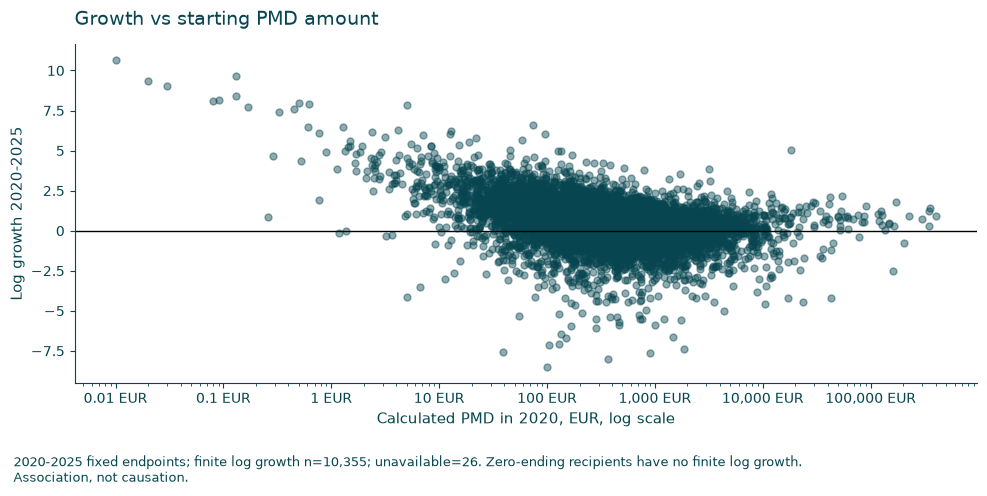

In [13]:
from chart_style import finish_chart, growth_boxplot, contrast_text

plt.figure(figsize=(10, 5))
plt.scatter(
    growth_driver_table["first_year_amount"],
    growth_driver_table["whole_period_log_growth"],
    alpha=0.45,
    color=CHART_COLORS["primary"]
)
plt.xscale("log")
plt.axhline(0, color="black", linewidth=1)
plt.title("Growth vs starting PMD amount")
plt.xlabel("Calculated PMD in 2020, EUR, log scale")
plt.ylabel("Log growth 2020-2025")

finish_chart(plt.gcf(), f"2020-2025 fixed endpoints; finite log growth n={growth_driver_table.whole_period_log_growth.notna().sum():,}; unavailable={growth_driver_table.whole_period_log_growth.isna().sum():,}. Zero-ending recipients have no finite log growth. Association, not causation.")

## What changed alongside whole-period funding growth?

Recipients with growing funding and comparable positive denominators are classified into three patterns: more requests only, higher funding per request only, and both increasing. 'Only' means the other measure stayed unchanged or decreased. Funding equals requests multiplied by funding per request, so growth factors multiply; percentage changes must not be added. These are accompanying changes, not causal contributions, and requests are not unique supporters.

In [14]:
from growth_components import compare_growth_components, GROWTH_PATTERNS

growth_components = compare_growth_components(recipient_year_amounts, START_YEAR, END_YEAR)
component_coverage = growth_components.groupby(
    ["comparison_status", "growth_pattern"], dropna=False
).agg(unique_recipients=("recipient_code", "nunique"))
display(component_coverage)

growing_components = growth_components.loc[
    growth_components["growth_pattern"].isin(GROWTH_PATTERNS)
].copy()
component_summary = growing_components.groupby("growth_pattern").agg(
    unique_recipients=("recipient_code", "nunique"),
    median_funding_growth=("amount_growth_pct", "median"),
    median_request_growth=("requests_growth_pct", "median"),
    median_per_request_growth=("amount_per_request_growth_pct", "median"),
).reindex(GROWTH_PATTERNS)
component_summary["unique_recipients"] = component_summary["unique_recipients"].fillna(0).astype(int)
component_summary["share_of_comparable_growing_recipients"] = (
    component_summary["unique_recipients"] / len(growing_components)
    if len(growing_components) else np.nan
)
assert component_summary["unique_recipients"].sum() == len(growing_components)
display(component_summary.style.format({
    "unique_recipients": "{:,.0f}",
    **{c: "{:.1%}" for c in component_summary.columns if c != "unique_recipients"},
}, na_rep="No data"))

unique_recipients
comparison_status           growth_pattern                                    
Available                   Both increased                                3955
                            Higher funding per request only               2739
                            More requests only                             577
                            No funding increase                           3110
Invalid or zero denominator Not comparable                                  27
Missing endpoint data       Not comparable                               12993

,unique_recipients,median_funding_growth,median_request_growth,median_per_request_growth,share_of_comparable_growing_recipients
growth_pattern,,,,,
More requests only,577,83.1%,150.0%,-19.4%,7.9%
Higher funding per request only,"2,739",51.0%,-20.8%,106.6%,37.7%
Both increased,"3,955",240.4%,83.3%,73.0%,54.4%


## Frequency of growth patterns

Bars count comparable growing recipients, not their contribution to total funding growth. The coverage table above also reports unavailable comparisons and recipients without increased funding.

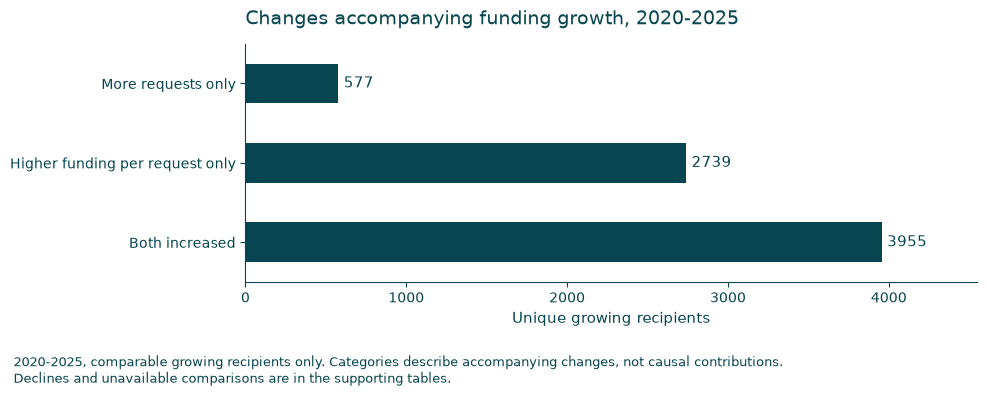

,unique_recipients,median_funding_growth,median_request_growth,median_per_request_growth,share_of_comparable_growing_recipients
growth_pattern,,,,,
More requests only,577,0.831269,1.500000,-0.194315,0.079356
Higher funding per request only,2739,0.510227,-0.208333,1.065712,0.376702
Both increased,3955,2.403642,0.833333,0.729941,0.543942


In [15]:
from chart_style import finish_chart, growth_boxplot, contrast_text

ax = component_summary["unique_recipients"].iloc[::-1].plot.barh(
    figsize=(10, 4), color=CHART_COLORS["primary"]
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)
ax.set_xlim(0, max(1, component_summary["unique_recipients"].max()) * 1.15)
ax.set_title(f"Changes accompanying funding growth, {START_YEAR}-{END_YEAR}")
ax.set_xlabel("Unique growing recipients")
ax.set_ylabel("")

finish_chart(plt.gcf(), '2020-2025, comparable growing recipients only. Categories describe accompanying changes, not causal contributions. Declines and unavailable comparisons are in the supporting tables.')
display(component_summary)


## Recipient examples within each growth pattern

The displayed examples use the same classifications as the bars. Endpoint amounts and request counts make the classifications traceable. The exported comparison CSV retains all recipients, including unavailable comparisons.

In [16]:
component_columns = [
    "recipient_name", "growth_pattern", "start_amount", "end_amount",
    "start_requests", "end_requests", "start_amount_per_request",
    "end_amount_per_request", "amount_growth_pct", "requests_growth_pct",
    "amount_per_request_growth_pct",
]
component_details = growing_components.sort_values(
    ["growth_pattern", "amount_growth_pct"], ascending=[True, False]
)
for pattern in GROWTH_PATTERNS:
    group = component_details.loc[component_details["growth_pattern"].eq(pattern)]
    print(f"{pattern}: {len(group):,} recipients; showing up to 20")
    display(group[component_columns].head(20).style.format({
        **{c: "{:,.2f} EUR" for c in ["start_amount", "end_amount", "start_amount_per_request", "end_amount_per_request"]},
        **{c: "{:,.0f}" for c in ["start_requests", "end_requests"]},
        **{c: "{:.1%}" for c in ["amount_growth_pct", "requests_growth_pct", "amount_per_request_growth_pct"]},
    }, na_rep="No data"))
growth_components.to_csv(PROJECT_ROOT / "outputs/growth_components.csv", index=False, encoding="utf-8-sig")

More requests only: 577 recipients; showing up to 20


,recipient_name,growth_pattern,start_amount,end_amount,start_requests,end_requests,start_amount_per_request,end_amount_per_request,amount_growth_pct,requests_growth_pct,amount_per_request_growth_pct
5051,Lietuvos evangelikų reformatų senjoratas,More requests only,96.60 EUR,"7,438.83 EUR",1,112,96.60 EUR,66.42 EUR,7600.7%,11100.0%,-31.2%
7034,Vaiko raidos klinika,More requests only,160.88 EUR,"9,268.80 EUR",3,177,53.63 EUR,52.37 EUR,5661.3%,5800.0%,-2.4%
11665,Darbuotojų ir valstybės tarnautojų profesinė sąjunga,More requests only,45.11 EUR,"2,104.47 EUR",1,59,45.11 EUR,35.67 EUR,4565.2%,5800.0%,-20.9%
11942,Juozo Miltinio dramos teatro aktorių profesinė sąjunga,More requests only,67.32 EUR,"2,490.15 EUR",1,54,67.32 EUR,46.11 EUR,3599.0%,5300.0%,-31.5%
1361,"Biržų dziudo sporto klubas ""ROONI""",More requests only,56.64 EUR,"1,623.97 EUR",1,35,56.64 EUR,46.40 EUR,2767.2%,3400.0%,-18.1%
18721,VšĮ Stiprūs Kartu,More requests only,600.49 EUR,"16,278.16 EUR",6,213,100.08 EUR,76.42 EUR,2610.8%,3450.0%,-23.6%
10436,"Vaikų ligoninės VšĮ VULSK filialo reabilitacijos skyriaus Druskininkų ""Saulutė"" profesinė sąjunga ""Solidarumas""",More requests only,29.32 EUR,733.68 EUR,1,29,29.32 EUR,25.30 EUR,2402.3%,2800.0%,-13.7%
5843,"Klaipėdos apskrities moterų, sergančių onkologinėmis ligomis, draugija ""Zunda""",More requests only,48.86 EUR,"1,082.15 EUR",1,24,48.86 EUR,45.09 EUR,2114.8%,2300.0%,-7.7%
3286,Lietuvos žemės ūkio darbuotojų profesinių sąjungų federacijos Radviliškio rajono komitetas,More requests only,28.54 EUR,541.49 EUR,1,19,28.54 EUR,28.50 EUR,1797.3%,1800.0%,-0.1%
16367,"Asociacija ""Telšių futbolo mėgėjas""",More requests only,132.78 EUR,"2,487.29 EUR",2,39,66.39 EUR,63.78 EUR,1773.2%,1850.0%,-3.9%


Higher funding per request only: 2,739 recipients; showing up to 20


,recipient_name,growth_pattern,start_amount,end_amount,start_requests,end_requests,start_amount_per_request,end_amount_per_request,amount_growth_pct,requests_growth_pct,amount_per_request_growth_pct
13938,"VšĮ ""Olimpinė viltis""",Higher funding per request only,15.27 EUR,"3,269.95 EUR",2,1,7.63 EUR,"3,269.95 EUR",21314.2%,-50.0%,42728.4%
11911,"VšĮ ""Verslas ar menas""",Higher funding per request only,0.52 EUR,39.94 EUR,1,1,0.52 EUR,39.94 EUR,7580.8%,0.0%,7580.8%
704,"Viešoji įstaiga ""Lututės"" leidykla",Higher funding per request only,5.30 EUR,395.00 EUR,3,2,1.77 EUR,197.50 EUR,7352.8%,-33.3%,11079.2%
738,"Kauno jaunimo golfo klubas ""Svingas""",Higher funding per request only,89.97 EUR,"5,013.53 EUR",2,2,44.98 EUR,"2,506.76 EUR",5472.4%,0.0%,5472.4%
17457,"VšĮ ""Padūmio projektai""",Higher funding per request only,782.95 EUR,"35,608.49 EUR",11,9,71.18 EUR,"3,956.50 EUR",4448.0%,-18.2%,5458.7%
4387,Lietuvos gidų gildija,Higher funding per request only,1.69 EUR,68.93 EUR,1,1,1.69 EUR,68.93 EUR,3978.7%,0.0%,3978.7%
11055,"VšĮ ""Tumbao""",Higher funding per request only,2.08 EUR,55.49 EUR,1,1,2.08 EUR,55.49 EUR,2567.8%,0.0%,2567.8%
6121,"Labdaros ir paramos fondas ""Laisva valia""",Higher funding per request only,2.47 EUR,65.67 EUR,2,1,1.24 EUR,65.67 EUR,2558.7%,-50.0%,5217.4%
16267,"Utenos subaru klubas ""Subaforis""",Higher funding per request only,2.79 EUR,71.21 EUR,2,2,1.40 EUR,35.60 EUR,2452.3%,0.0%,2452.3%
10612,SĄNARIŲ ENDOPROTEZUOTOJŲ ASOCIACIJA,Higher funding per request only,12.71 EUR,321.91 EUR,1,1,12.71 EUR,321.91 EUR,2432.7%,0.0%,2432.7%


Both increased: 3,955 recipients; showing up to 20


,recipient_name,growth_pattern,start_amount,end_amount,start_requests,end_requests,start_amount_per_request,end_amount_per_request,amount_growth_pct,requests_growth_pct,amount_per_request_growth_pct
16492,Asociacija Lietuvos suaugusių alkoholikų vaikų bendrija,Both increased,0.01 EUR,434.72 EUR,1,9,0.01 EUR,48.30 EUR,4347100.0%,800.0%,482922.2%
4013,Kauno miesto musulmonų religinė bendruomenė,Both increased,0.13 EUR,"2,027.81 EUR",1,35,0.13 EUR,57.94 EUR,1559753.8%,3400.0%,44467.3%
12992,Lengvosios atletikos asociacija,Both increased,0.02 EUR,235.81 EUR,1,4,0.02 EUR,58.95 EUR,1178950.0%,300.0%,294662.5%
6725,"Krikščionių misija ""Aušra""",Both increased,0.03 EUR,250.11 EUR,1,7,0.03 EUR,35.73 EUR,833600.0%,600.0%,119000.0%
5054,Lazdijų sentikių religinė bendruomenė,Both increased,0.13 EUR,582.35 EUR,1,13,0.13 EUR,44.80 EUR,447861.5%,1200.0%,34358.6%
1386,Geidžiūnų bendruomenė,Both increased,0.09 EUR,311.87 EUR,1,10,0.09 EUR,31.19 EUR,346422.2%,900.0%,34552.2%
6907,"Labdaros ir paramos fondas ""VILTIES KALNAS""",Both increased,0.08 EUR,264.24 EUR,1,7,0.08 EUR,37.75 EUR,330200.0%,600.0%,47085.7%
8963,Lietuvių skalikų augintojų sąjunga,Both increased,0.50 EUR,"1,461.97 EUR",1,23,0.50 EUR,63.56 EUR,292294.0%,2200.0%,12612.8%
12445,"Sporto klubas ""Šilalės lūšis""",Both increased,0.62 EUR,"1,718.62 EUR",1,39,0.62 EUR,44.07 EUR,277096.8%,3800.0%,7007.6%
6249,Lietuvos švietimo darbuotojų profesinės sąjungos Alytaus miesto susivienijimas,Both increased,5.07 EUR,"12,678.62 EUR",1,372,5.07 EUR,34.08 EUR,249971.4%,37100.0%,572.2%


## Growth patterns in consecutive-year comparisons

The same classification is applied separately to 2020-2021 through 2024-2025. Missing endpoints and zero denominators are reported separately. The comparable recipients can differ between years, so shifts in shares can reflect both changed behavior and changed sample composition.

In [17]:
from growth_components import compare_growth_components, GROWTH_PATTERNS

annual_results = []

for start_year in range(START_YEAR, END_YEAR):
    result = compare_growth_components(
        recipient_year_amounts,
        start=start_year,
        end=start_year + 1,
    )
    result["period"] = f"{start_year}-{start_year + 1}"
    annual_results.append(result)

annual_growth_patterns = pd.concat(annual_results, ignore_index=True)

# Include unavailable comparisons and recipients without funding increases.
annual_coverage = annual_growth_patterns.pivot_table(
    index="period",
    columns="growth_pattern",
    values="recipient_code",
    aggfunc="nunique",
    fill_value=0,
)

display(annual_coverage)

annual_pattern_counts = annual_coverage.reindex(
    columns=GROWTH_PATTERNS, fill_value=0
)

growing_recipients = annual_pattern_counts.sum(axis=1)

annual_pattern_shares = annual_pattern_counts.div(
    growing_recipients.where(growing_recipients > 0),
    axis=0,
)

display(annual_pattern_shares.style.format("{:.1%}", na_rep="No data"))

growth_pattern,Both increased,Higher funding per request only,More requests only,No funding increase,Not comparable
period,,,,,
2020-2021,3048,4279,1277,6201,8596
2021-2022,2926,3799,1179,6272,9225
2022-2023,2955,3505,1342,6241,9358
2023-2024,4246,2504,1604,4264,10783
2024-2025,3028,2306,1886,6155,10026


growth_pattern,More requests only,Higher funding per request only,Both increased
period,,,
2020-2021,14.8%,49.7%,35.4%
2021-2022,14.9%,48.1%,37.0%
2022-2023,17.2%,44.9%,37.9%
2023-2024,19.2%,30.0%,50.8%
2024-2025,26.1%,31.9%,41.9%


## Annual growth-pattern shares

Each bar describes only that pair's comparable growing recipients, with its count shown below. Similar shares suggest a recurring mix of accompanying changes; a sharp shift identifies a year to investigate. These shares do not establish which year contributed most euros to overall growth.

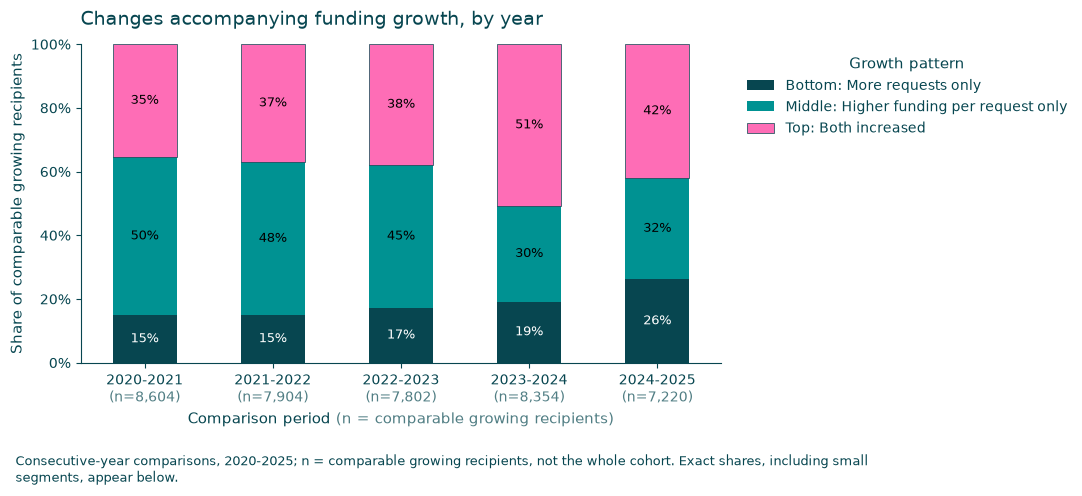

growth_pattern,More requests only,Higher funding per request only,Both increased
period,,,
2020-2021,0.148419,0.497327,0.354254
2021-2022,0.149165,0.480643,0.370192
2022-2023,0.172007,0.449244,0.378749
2023-2024,0.192004,0.299737,0.508260
2024-2025,0.261219,0.319391,0.419391


In [18]:
from chart_style import finish_chart, growth_boxplot, contrast_text

ax = annual_pattern_shares.plot.bar(
    stacked=True,
    figsize=(11, 5),
    color=[
        CHART_COLORS["primary"],
        CHART_COLORS["secondary"],
        CHART_COLORS["accent"],
    ],
)

ax.set_xticklabels(
    [
        f"{period}\n(n={int(count):,})"
        for period, count in growing_recipients.items()
    ],
    rotation=0,
)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.0%}"))
ax.set_title("Changes accompanying funding growth, by year")
ax.set_xlabel("Comparison period (n = comparable growing recipients)")
ax.set_ylabel("Share of comparable growing recipients")
ax.legend([f"{position}: {pattern}" for position, pattern in zip(["Bottom", "Middle", "Top"], annual_pattern_shares.columns)], title="Growth pattern", bbox_to_anchor=(1.02, 1), loc="upper left")
for container in ax.containers:
    labels = [f"{v:.0%}" if v >= .04 else "" for v in container.datavalues]
    texts = ax.bar_label(container, labels=labels, label_type="center", fontsize=9)
    for text, bar in zip(texts, container):
        text.set_color(contrast_text(bar.get_facecolor()))
        text.set_bbox(dict(facecolor=bar.get_facecolor(), edgecolor="none", pad=1))
finish_chart(plt.gcf(), 'Consecutive-year comparisons, 2020-2025; n = comparable growing recipients, not the whole cohort. Exact shares, including small segments, appear below.')
display(annual_pattern_shares)


## Growth by organization age in 2025

Age is tax year minus registration year, not exact birthday-based age. These end-of-period groups differ from starting age and from first-top-1% age. Boxes summarize defined log-growth values; Unknown retains unavailable age. Group differences are descriptive, not evidence that age caused growth.

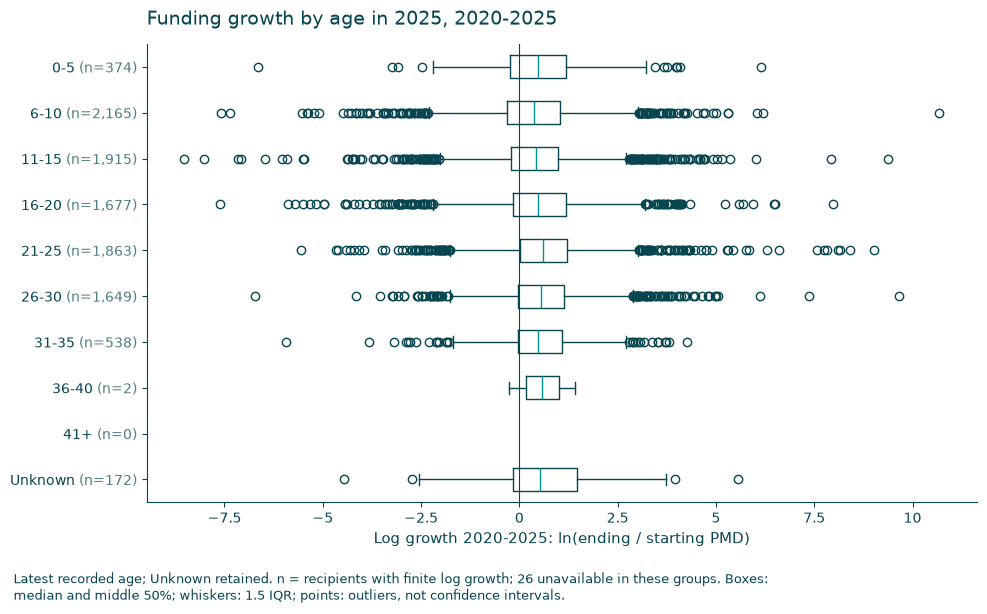

,count,median,min,max
organization_age_group,,,,
0-5,374,0.476319,-6.642018,6.149136
6-10,2165,0.369385,-7.576610,10.679872
11-15,1915,0.418416,-8.517893,9.375049
16-20,1677,0.482960,-7.617726,7.980687
21-25,1863,0.595946,-5.563746,9.028459
26-30,1649,0.552961,-6.727764,9.654933
31-35,538,0.484366,-5.923007,4.266261
36-40,2,0.583133,-0.261397,1.427663
41+,0,NaN,NaN,NaN


In [19]:
from chart_style import finish_chart, growth_boxplot, contrast_text

age_order = [
    "0-5", "6-10", "11-15", "16-20", "21-25",
    "26-30", "31-35", "36-40", "41+", "Unknown"
]

plot_age = growth_driver_table.copy()
plot_age["organization_age_group"] = pd.Categorical(
    plot_age["organization_age_group"],
    categories=age_order,
    ordered=True
)

growth_boxplot(plot_age, "organization_age_group", age_order, f"Funding growth by age in {END_YEAR}, 2020-2025", "Latest recorded age; Unknown retained.")
display(plot_age.groupby("organization_age_group", observed=False)["whole_period_log_growth"].agg(["count", "median", "min", "max"]))


## Growth by legal form

The chart includes up to ten of the most common forms in the fixed-endpoint sample. A higher median describes higher observed log growth among comparable recipients, not a structural advantage of the legal form. Unequal group sizes, starting amounts and within-group variation limit comparisons.

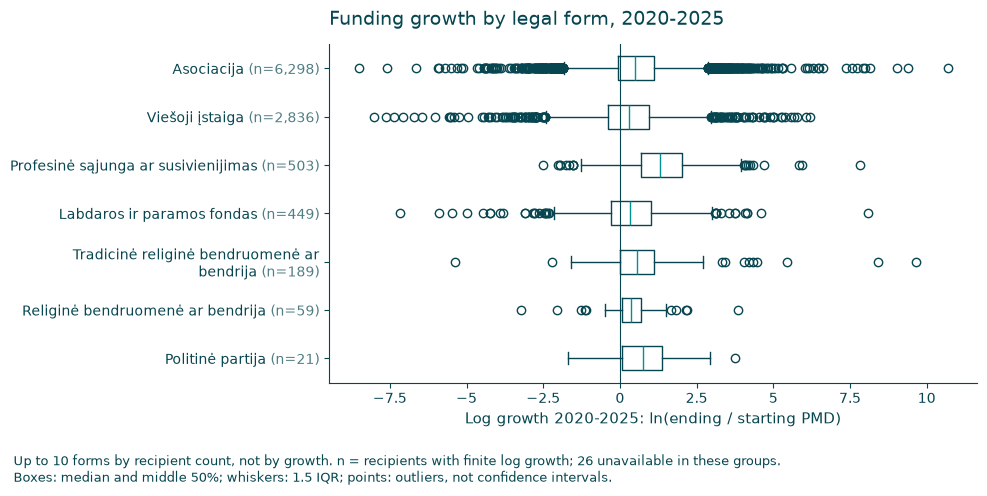

,count,median,min,max
legal_form_clean,,,,
Asociacija,6298,0.500750,-8.517893,10.679872
Labdaros ir paramos fondas,449,0.335708,-7.163269,8.102586
Politinė partija,21,0.755051,-1.699749,3.755549
Profesinė sąjunga ar susivienijimas,503,1.308128,-2.498269,7.824332
Religinė bendruomenė ar bendrija,59,0.376559,-3.215576,3.842298
Tradicinė religinė bendruomenė ar bendrija,189,0.560461,-5.381952,9.654933
Viešoji įstaiga,2836,0.299652,-8.021174,6.193372


In [20]:
from chart_style import finish_chart, growth_boxplot, contrast_text

top_legal_forms = growth_driver_table["legal_form_clean"].value_counts().head(10).index

plot_legal = growth_driver_table[
    growth_driver_table["legal_form_clean"].isin(top_legal_forms)
].copy()

growth_boxplot(plot_legal, "legal_form_clean", top_legal_forms, "Funding growth by legal form, 2020-2025", "Up to 10 forms by recipient count, not by growth.")
display(plot_legal.groupby("legal_form_clean", observed=False)["whole_period_log_growth"].agg(["count", "median", "min", "max"]))


## Municipality coverage and valid sample sizes

The coverage table distinguishes total recipients from valid log-growth recipients. The minimum of ten applies to finite log-growth observations, while funding and request totals still cover all recipients in the fixed-endpoint table. The coverage table retains small and unassigned groups; ten observations is a screening rule, not a guarantee of statistical reliability.

In [21]:
# Count the sample used by the log statistics, not only available percentage growth.
municipality_log_data = growth_driver_table.copy()
valid_log = np.isfinite(municipality_log_data["whole_period_log_growth"])
municipality_log_data["whole_period_log_growth"] = (
    municipality_log_data["whole_period_log_growth"].where(valid_log)
)
municipality_log_data["valid_log_recipient_code"] = (
    municipality_log_data["recipient_code"].where(valid_log)
)

municipality_growth_coverage = (
    municipality_log_data
    .groupby("municipality", as_index=False, dropna=False)
    .agg(
        total_recipients=("recipient_code", "nunique"),
        valid_log_growth_recipients=("valid_log_recipient_code", "nunique"),
        median_growth=("whole_period_log_growth", "median"),
        mean_growth=("whole_period_log_growth", "mean"),
        total_pmd_eur=("total_pmd_eur", "sum"),
        total_requests=("total_requests", "sum"),
    )
)
municipality_growth_coverage["excluded_from_log_growth"] = (
    municipality_growth_coverage["total_recipients"]
    - municipality_growth_coverage["valid_log_growth_recipients"]
)
municipality_growth_summary = (
    municipality_growth_coverage
    .query("valid_log_growth_recipients >= 10")
    .sort_values("median_growth", ascending=False)
    .copy()
)
display(municipality_growth_summary.head(20))
print("Municipalities below the minimum of 10 valid log-growth recipients:")
display(municipality_growth_coverage.query("valid_log_growth_recipients < 10"))

,municipality,total_recipients,valid_log_growth_recipients,median_growth,mean_growth,total_pmd_eur,total_requests,excluded_from_log_growth
17,Kelmės r. sav.,79,79,0.899271,0.821528,342464.17,7260,0
21,Kupiškio r. sav.,66,66,0.886400,1.048633,255009.82,4635,0
23,Lazdijų r. sav.,74,74,0.861975,0.852369,343391.51,7378,0
28,Pagėgių sav.,30,29,0.851847,0.700917,81286.82,1782,1
52,Šakių r. sav.,100,100,0.795185,0.787863,369687.49,7337,0
55,Šiaulių r. sav.,129,129,0.776701,0.706404,1602151.37,36041,0
35,Prienų r. sav.,93,93,0.729114,0.717418,456114.17,9743,0
34,Plungės r. sav.,106,105,0.718689,0.943479,712931.90,13572,1
57,Šilutės r. sav.,108,108,0.718012,0.794110,625629.54,14857,0
20,Kretingos r. sav.,102,102,0.711555,0.673770,472182.19,10099,0


Municipalities below the minimum of 10 valid log-growth recipients:


,municipality,total_recipients,valid_log_growth_recipients,median_growth,mean_growth,total_pmd_eur,total_requests,excluded_from_log_growth


## Growth distributions in selected municipalities

These are the first 20 municipalities from the eligible summary, not all municipalities. Values describe organizations assigned to their latest recorded municipality, not local residents' donations or population-adjusted outcomes. Differences do not establish stronger local growth conditions.

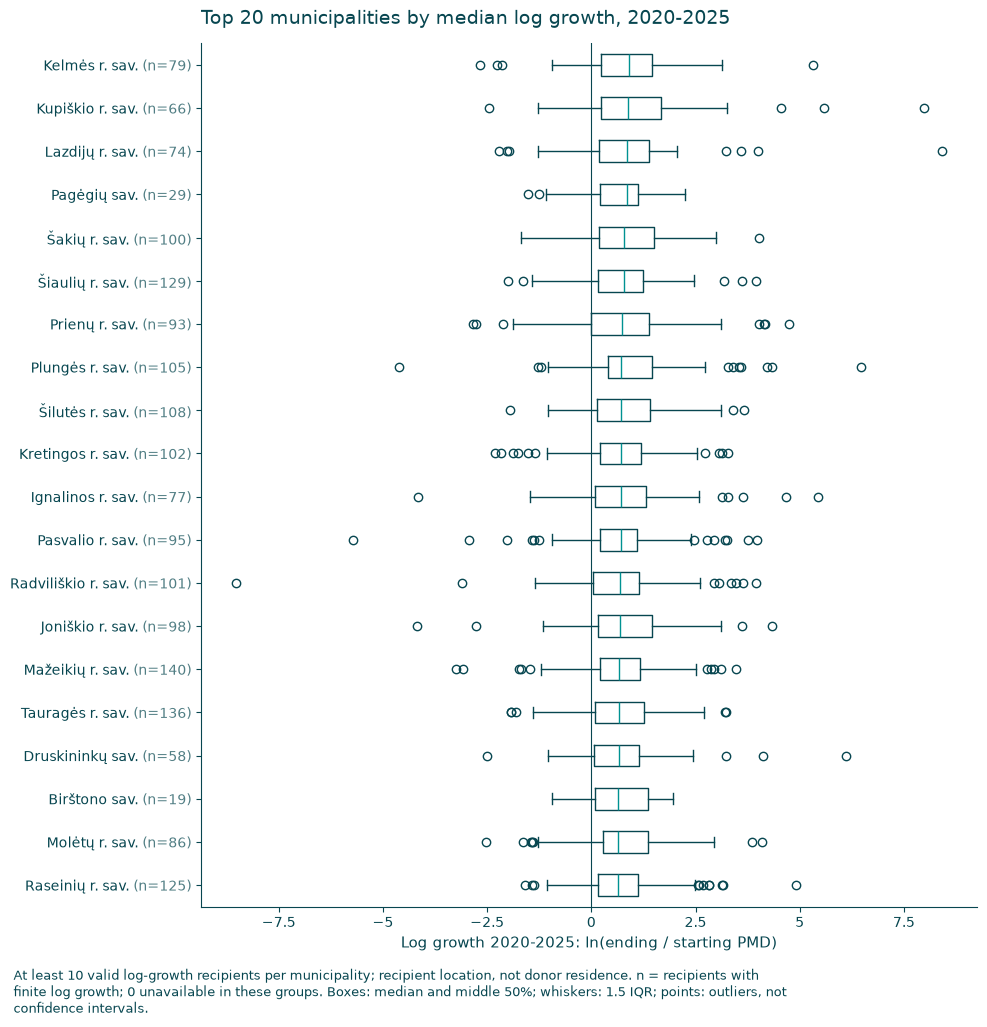

,count,median,min,max
municipality,,,,
Birštono sav.,19,0.646767,-0.945949,1.949655
Druskininkų sav.,58,0.652640,-2.498269,6.108410
Ignalinos r. sav.,77,0.710167,-4.146932,5.441970
Joniškio r. sav.,98,0.685681,-4.190564,4.327102
Kelmės r. sav.,79,0.899271,-2.673824,5.309471
Kretingos r. sav.,102,0.711555,-2.317641,3.277316
Kupiškio r. sav.,66,0.886400,-2.444115,7.980687
Lazdijų r. sav.,74,0.861975,-2.215354,8.407292
Mažeikių r. sav.,140,0.673852,-3.240012,3.464139


In [22]:
from chart_style import finish_chart, growth_boxplot, contrast_text

top_municipalities = municipality_growth_summary.head(20)["municipality"]

plot_municipality = growth_driver_table[
    (growth_driver_table["municipality"].isin(top_municipalities))
    & np.isfinite(growth_driver_table["whole_period_log_growth"])
].copy()

growth_boxplot(plot_municipality, "municipality", top_municipalities, "Top 20 municipalities by median log growth, 2020-2025", "At least 10 valid log-growth recipients per municipality; recipient location, not donor residence.")
display(plot_municipality.groupby("municipality", observed=False)["whole_period_log_growth"].agg(["count", "median", "min", "max"]))


## Descriptive correlations

The matrix uses pairwise nonmissing observations, so sample sizes can differ across pairs. Full-period totals, endpoint amounts and growth overlap arithmetically and in time. Correlations therefore are not independent predictors or causal effects; the plots and outliers provide context for their interpretation.

In [23]:
correlation_columns = [
    "whole_period_log_growth",
    "average_log_growth",
    "first_year_amount",
    "last_year_amount",
    "total_pmd_eur",
    "total_requests",
    "average_amount_per_request",
    "positive_growth_years",
    "negative_growth_years",
    "organization_age"
]

growth_driver_table[correlation_columns].corr()

,whole_period_log_growth,average_log_growth,first_year_amount,last_year_amount,total_pmd_eur,total_requests,average_amount_per_request,positive_growth_years,negative_growth_years,organization_age
whole_period_log_growth,1.000000,0.753683,-0.023918,0.058961,0.041749,0.039003,-0.039705,0.463371,-0.494524,0.068286
average_log_growth,0.753683,1.000000,-0.015171,0.046706,0.033482,0.031645,-0.025220,0.448746,-0.437039,0.056055
first_year_amount,-0.023918,-0.015171,1.000000,0.645763,0.641516,0.765814,0.019975,0.050811,-0.022920,-0.001721
last_year_amount,0.058961,0.046706,0.645763,1.000000,0.986088,0.950842,0.004798,0.070889,-0.056379,-0.014545
total_pmd_eur,0.041749,0.033482,0.641516,0.986088,1.000000,0.962270,0.010764,0.057823,-0.039383,-0.012107
total_requests,0.039003,0.031645,0.765814,0.950842,0.962270,1.000000,-0.012240,0.067859,-0.046514,-0.006554
average_amount_per_request,-0.039705,-0.025220,0.019975,0.004798,0.010764,-0.012240,1.000000,-0.026388,0.024011,-0.043482
positive_growth_years,0.463371,0.448746,0.050811,0.070889,0.057823,0.067859,-0.026388,1.000000,-0.631433,0.040083
negative_growth_years,-0.494524,-0.437039,-0.022920,-0.056379,-0.039383,-0.046514,0.024011,-0.631433,1.000000,-0.042396
organization_age,0.068286,0.056055,-0.001721,-0.014545,-0.012107,-0.006554,-0.043482,0.040083,-0.042396,1.000000


## Recipient-level results

This rounded preview combines fixed-period growth, full-period requests, average funding per request and observed annual growth counts. Counts of positive and negative years exclude unavailable annual comparisons; they do not by themselves measure volatility.

In [24]:
growth_driver_table_display = growth_driver_table[
    [
        "recipient_name",
        "municipality",
        "legal_form_clean",
        "organization_age_group",
        "first_year_amount",
        "last_year_amount",
        "total_requests",
        "average_amount_per_request",
        "whole_period_growth_pct",
        "whole_period_log_growth",
        "positive_growth_years",
        "negative_growth_years"
    ]
].copy()

growth_driver_table_display["first_year_amount"] = growth_driver_table_display["first_year_amount"].round(2)
growth_driver_table_display["last_year_amount"] = growth_driver_table_display["last_year_amount"].round(2)
growth_driver_table_display["average_amount_per_request"] = growth_driver_table_display["average_amount_per_request"].round(2)
growth_driver_table_display["whole_period_growth_pct"] = growth_driver_table_display["whole_period_growth_pct"].round(3)
growth_driver_table_display["whole_period_log_growth"] = growth_driver_table_display["whole_period_log_growth"].round(3)

growth_driver_table_display.head(30)

,recipient_name,municipality,legal_form_clean,organization_age_group,first_year_amount,last_year_amount,total_requests,average_amount_per_request,whole_period_growth_pct,whole_period_log_growth,positive_growth_years,negative_growth_years
16492,Asociacija Lietuvos suaugusių alkoholikų vaikų...,Vilniaus m. sav.,Asociacija,6-10,0.01,434.72,15,42.93,43471.000,10.680,1,0
4013,Kauno miesto musulmonų religinė bendruomenė,Kauno m. sav.,Tradicinė religinė bendruomenė ar bendrija,26-30,0.13,2027.81,76,57.80,15597.538,9.655,5,0
12992,Lengvosios atletikos asociacija,Vilniaus m. sav.,Asociacija,11-15,0.02,235.81,10,37.51,11789.500,9.375,4,1
6725,"Krikščionių misija ""Aušra""",Marijampolės sav.,Asociacija,21-25,0.03,250.11,22,35.96,8336.000,9.028,0,2
5054,Lazdijų sentikių religinė bendruomenė,Lazdijų r. sav.,Tradicinė religinė bendruomenė ar bendrija,21-25,0.13,582.35,30,39.10,4478.615,8.407,5,0
1386,Geidžiūnų bendruomenė,Biržų r. sav.,Asociacija,21-25,0.09,311.87,45,18.31,3464.222,8.151,4,1
6907,"Labdaros ir paramos fondas ""VILTIES KALNAS""",Šiaulių m. sav.,Labdaros ir paramos fondas,21-25,0.08,264.24,15,28.06,3302.000,8.103,3,2
8963,Lietuvių skalikų augintojų sąjunga,Kupiškio r. sav.,Asociacija,16-20,0.50,1461.97,50,57.35,2922.940,7.981,4,1
12445,"Sporto klubas ""Šilalės lūšis""",Šilalės r. sav.,Asociacija,11-15,0.62,1718.62,114,58.53,2770.968,7.927,2,1
6249,Lietuvos švietimo darbuotojų profesinės sąjung...,Vilniaus m. sav.,Profesinė sąjunga ar susivienijimas,21-25,5.07,12678.62,868,31.30,2499.714,7.824,5,0


## Additional perspectives on funding growth

How much funding changed, which recipients contributed to recorded totals, and whether annual patterns persist in a stable sample are separate questions. These additional views retain the shared legal-form cohort and the existing annual and whole-period analyses.

Recipients are identified by code. Missing observations remain missing. Pattern counts describe frequency, while euro changes describe financial scale; neither establishes causes.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display
from cohort import START_YEAR, END_YEAR
from growth_components import compare_growth_components, GROWTH_PATTERNS

if "recipient_year_amounts" not in globals():
    raise RuntimeError("Run this notebook from the beginning first.")

extra_annual = recipient_year_amounts.loc[
    recipient_year_amounts["tax_year"].between(START_YEAR, END_YEAR)
].copy()
required_years = set(range(START_YEAR, END_YEAR + 1))
if required_years - set(extra_annual["tax_year"]):
    raise ValueError("A required analysis year is missing from the cohort.")
if extra_annual.duplicated(["recipient_code", "tax_year"]).any():
    raise ValueError("Expected one record per recipient code and year.")
values = extra_annual[["amount", "requests"]]
if not np.isfinite(values).all().all() or values.lt(0).any().any():
    raise ValueError("Review missing, nonfinite or negative recorded measures first.")

money_format = "{:,.2f} EUR"
count_format = "{:,.0f}"

### How much funding changed within each pattern?

For comparable endpoints, the table shows unique recipients, starting funding, ending funding and the net euro change within each group. Growing recipients retain the existing three patterns. Declining and unchanged recipients appear separately.

These are changes within groups, not amounts caused by requests or funding per request. Recipients without a valid requests/per-request comparison are reported separately. In particular, a zero-request endpoint can prevent this comparison even when funding change itself is measurable.

In [26]:
extra_components = compare_growth_components(
    extra_annual, START_YEAR, END_YEAR
)
extra_available = extra_components["comparison_status"].eq("Available")
extra_comparable = extra_components.loc[extra_available].copy()
extra_comparable["euro_group"] = extra_comparable["growth_pattern"]
extra_comparable.loc[
    extra_comparable["end_amount"].lt(extra_comparable["start_amount"]),
    "euro_group",
] = "Funding decreased"
extra_comparable.loc[
    extra_comparable["end_amount"].eq(extra_comparable["start_amount"]),
    "euro_group",
] = "Funding unchanged"
extra_comparable["change_eur"] = (
    extra_comparable["end_amount"] - extra_comparable["start_amount"]
)
extra_group_order = GROWTH_PATTERNS + ["Funding decreased", "Funding unchanged"]
pattern_euros = (
    extra_comparable.groupby("euro_group")
    .agg(
        unique_recipients=("recipient_code", "nunique"),
        starting_funding_eur=("start_amount", "sum"),
        ending_funding_eur=("end_amount", "sum"),
        change_eur=("change_eur", "sum"),
    )
    .reindex(extra_group_order, fill_value=0)
)
assert pattern_euros["unique_recipients"].sum() == len(extra_comparable)
assert np.isclose(
    pattern_euros["change_eur"].sum(),
    extra_comparable["end_amount"].sum() - extra_comparable["start_amount"].sum(),
    rtol=0, atol=0.01,
)
print(f"Comparable recipients: {len(extra_comparable):,}; {START_YEAR}-{END_YEAR}")
display(pattern_euros.style.format({
    "unique_recipients": count_format,
    **{c: money_format for c in pattern_euros if c != "unique_recipients"},
}))
print("Excluded from the requests/per-request comparison:")
pattern_unavailable = (
    extra_components.loc[~extra_available]
    .groupby("comparison_status")
    .agg(unique_recipients=("recipient_code", "nunique"))
)
display(pattern_unavailable)
assert len(extra_comparable) + pattern_unavailable["unique_recipients"].sum() == len(extra_components)

Comparable recipients: 10,381; 2020-2025


,unique_recipients,starting_funding_eur,ending_funding_eur,change_eur
euro_group,,,,
More requests only,577,"496,356.28 EUR","976,256.75 EUR","479,900.47 EUR"
Higher funding per request only,"2,739","3,232,613.64 EUR","4,703,276.55 EUR","1,470,662.91 EUR"
Both increased,"3,955","6,366,411.39 EUR","23,986,815.71 EUR","17,620,404.32 EUR"
Funding decreased,"3,110","4,188,071.34 EUR","2,022,158.75 EUR","-2,165,912.59 EUR"
Funding unchanged,0,0.00 EUR,0.00 EUR,0.00 EUR


Excluded from the requests/per-request comparison:


,unique_recipients
comparison_status,
Invalid or zero denominator,27
Missing endpoint data,12993


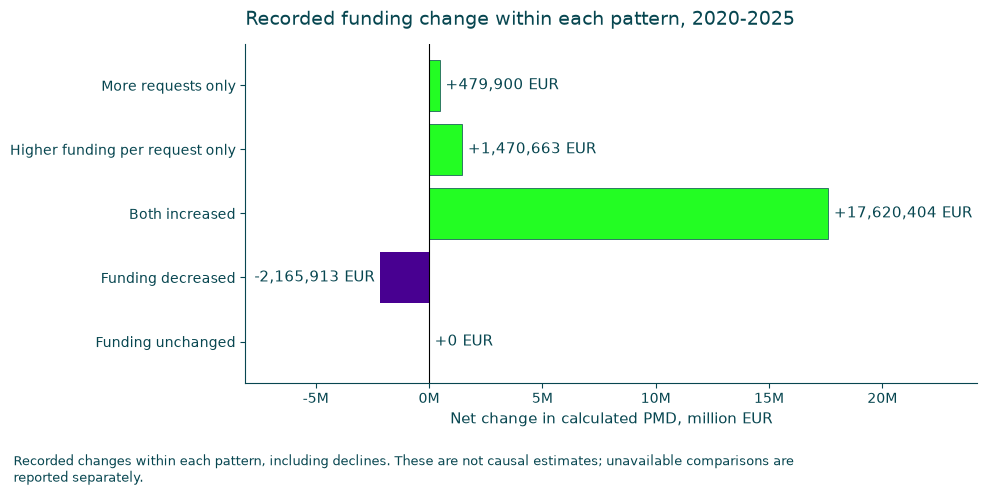

,unique_recipients,starting_funding_eur,ending_funding_eur,change_eur
euro_group,,,,
More requests only,577,496356.28,976256.75,479900.47
Higher funding per request only,2739,3232613.64,4703276.55,1470662.91
Both increased,3955,6366411.39,23986815.71,17620404.32
Funding decreased,3110,4188071.34,2022158.75,-2165912.59
Funding unchanged,0,0.00,0.00,0.00


In [27]:
from chart_style import finish_chart, growth_boxplot, contrast_text


plot_euros = pattern_euros.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    plot_euros.index, plot_euros["change_eur"],
    color=[CHART_COLORS["negative"] if v < 0 else CHART_COLORS["positive"]
           for v in plot_euros["change_eur"]],
)
ax.bar_label(bars, labels=[f"{v:+,.0f} EUR" for v in plot_euros["change_eur"]], padding=4)
ax.axvline(0, color="black", linewidth=0.8)
ax.margins(x=0.30)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M"))
ax.set_title(f"Recorded funding change within each pattern, {START_YEAR}-{END_YEAR}")
ax.set_xlabel("Net change in calculated PMD, million EUR")
ax.set_ylabel("")

finish_chart(plt.gcf(), 'Recorded changes within each pattern, including declines. These are not causal estimates; unavailable comparisons are reported separately.')
display(pattern_euros)


### What explains the difference between the recorded endpoint totals?

The full cohort is grouped by recorded presence at both endpoints, only the start, only the end, or neither endpoint. Recipients with recorded zero funding remain included.

The contribution column reconciles the difference between recorded totals. For start-only recipients it subtracts their recorded starting funding; for end-only recipients it adds their recorded ending funding. This is accounting for observed records, not an assumption that an absent recipient received zero, and not an individual growth rate.

End-only presence does not prove a new organization was established. Start-only presence does not prove closure. Recipients present only in intermediate years remain visible in the neither-endpoint group.

In [28]:
endpoint_presence = pd.DataFrame({
    "recipient_code": extra_annual["recipient_code"].unique()
})
for year, label in [(START_YEAR, "start"), (END_YEAR, "end")]:
    endpoint = extra_annual.loc[
        extra_annual["tax_year"].eq(year), ["recipient_code", "amount"]
    ].rename(columns={"amount": f"{label}_funding_eur"})
    endpoint[f"{label}_present"] = True
    endpoint_presence = endpoint_presence.merge(
        endpoint, on="recipient_code", how="left", validate="one_to_one"
    )
    endpoint_presence[f"{label}_present"] = endpoint_presence[f"{label}_present"].eq(True)

start_present = endpoint_presence["start_present"]
end_present = endpoint_presence["end_present"]
presence_order = ["Both endpoints", "Start only", "End only", "Neither endpoint"]
endpoint_presence["recorded_presence"] = np.select(
    [start_present & end_present, start_present & ~end_present, ~start_present & end_present],
    presence_order[:3], default=presence_order[3],
)
population_funding = (
    endpoint_presence.groupby("recorded_presence")
    .agg(
        unique_recipients=("recipient_code", "nunique"),
        start_funding_eur=("start_funding_eur", lambda s: s.sum(min_count=1)),
        end_funding_eur=("end_funding_eur", lambda s: s.sum(min_count=1)),
    )
    .reindex(presence_order)
)
population_funding["unique_recipients"] = population_funding["unique_recipients"].fillna(0).astype(int)
# Zeros here represent no recorded contribution to an aggregate, not imputed funding.
# The recipient-level endpoint amounts and displayed funding columns stay missing.
population_funding["contribution_to_recorded_change_eur"] = (
    population_funding["end_funding_eur"].fillna(0)
    - population_funding["start_funding_eur"].fillna(0)
)
start_total = extra_annual.loc[extra_annual["tax_year"].eq(START_YEAR), "amount"].sum()
end_total = extra_annual.loc[extra_annual["tax_year"].eq(END_YEAR), "amount"].sum()
assert population_funding["unique_recipients"].sum() == extra_annual["recipient_code"].nunique()
assert np.isclose(population_funding["start_funding_eur"].sum(), start_total, rtol=0, atol=0.01)
assert np.isclose(population_funding["end_funding_eur"].sum(), end_total, rtol=0, atol=0.01)
assert np.isclose(
    population_funding["contribution_to_recorded_change_eur"].sum(),
    end_total - start_total, rtol=0, atol=0.01,
)
print(f"Start = {START_YEAR}; end = {END_YEAR}")
display(population_funding.style.format({
    "unique_recipients": count_format,
    **{c: money_format for c in population_funding if c != "unique_recipients"},
}, na_rep="Not recorded"))
print(f"Recorded total: {start_total:,.2f} EUR -> {end_total:,.2f} EUR")
print(f"Difference between recorded totals: {end_total - start_total:+,.2f} EUR")

Start = 2020; end = 2025


,unique_recipients,start_funding_eur,end_funding_eur,contribution_to_recorded_change_eur
recorded_presence,,,,
Both endpoints,"10,408","14,283,452.65 EUR","31,697,508.15 EUR","17,414,055.50 EUR"
Start only,"6,340","2,969,600.53 EUR",Not recorded,"-2,969,600.53 EUR"
End only,"5,075",Not recorded,"8,427,116.59 EUR","8,427,116.59 EUR"
Neither endpoint,"1,578",Not recorded,Not recorded,0.00 EUR


Recorded total: 17,253,053.18 EUR -> 40,124,624.74 EUR
Difference between recorded totals: +22,871,571.56 EUR


### Do annual patterns persist when the eligible recipients stay fixed?

The available-pair view uses all recipients with valid data for each consecutive-year comparison. The stable sample is the intersection of recipients with valid requests/per-request comparisons in every annual pair across the analysis period. It is not a top-1% or persistent-top-1% sample.

Stable-sample membership is fixed, but the recipients whose funding grows can still change by year. The comparison therefore includes growing, declining and unchanged counts alongside pattern shares among growing recipients. Eligibility requires positive requests at both endpoints and a positive starting amount for each pair; a recorded zero ending amount is allowed by the shared helper.

The stable sample favors longer observed histories. Differences from the available-pair results indicate sensitivity to sample composition, not proof of a causal explanation.

In [29]:
extra_pair_results = {}
eligible_sets = []
for year in range(START_YEAR, END_YEAR):
    pair = compare_growth_components(extra_annual, year, year + 1)
    extra_pair_results[f"{year}-{year + 1}"] = pair
    eligible_sets.append(set(pair.loc[
        pair["comparison_status"].eq("Available"), "recipient_code"
    ]))
stable_codes = set.intersection(*eligible_sets)
print(f"Recipients valid for every consecutive-year comparison: {len(stable_codes):,}")

coverage_rows, share_rows, exclusion_rows = [], [], []
for period, pair in extra_pair_results.items():
    excluded = pair.loc[~pair["comparison_status"].eq("Available")]
    for reason, group in excluded.groupby("comparison_status"):
        exclusion_rows.append({"period": period, "reason": reason,
                               "unique_recipients": group["recipient_code"].nunique()})
    available = pair.loc[pair["comparison_status"].eq("Available")]
    stable = pair.loc[pair["recipient_code"].isin(stable_codes)]
    assert stable["comparison_status"].eq("Available").all()
    for sample, frame in [("Available pair", available), ("Stable sample", stable)]:
        delta = frame["end_amount"] - frame["start_amount"]
        growing = frame.loc[delta.gt(0)]
        coverage_rows.append({
            "period": period, "sample": sample,
            "comparable_recipients": len(frame), "growing": int(delta.gt(0).sum()),
            "declining": int(delta.lt(0).sum()), "unchanged": int(delta.eq(0).sum()),
        })
        counts = growing["growth_pattern"].value_counts().reindex(GROWTH_PATTERNS, fill_value=0)
        assert counts.sum() == len(growing)
        for pattern, count in counts.items():
            share_rows.append({
                "period": period, "sample": sample, "pattern": pattern,
                "share": count / len(growing) if len(growing) else np.nan,
            })

annual_sample_coverage = pd.DataFrame(coverage_rows).set_index(["period", "sample"])
assert annual_sample_coverage[["growing", "declining", "unchanged"]].sum(axis=1).eq(
    annual_sample_coverage["comparable_recipients"]
).all()
assert annual_sample_coverage.xs("Stable sample", level="sample")[
    "comparable_recipients"
].eq(len(stable_codes)).all()
annual_sample_shares = pd.DataFrame(share_rows).pivot(
    index=["period", "pattern"], columns="sample", values="share"
).reindex(columns=["Available pair", "Stable sample"])
annual_sample_shares["stable_minus_available_pp"] = 100 * (
    annual_sample_shares["Stable sample"] - annual_sample_shares["Available pair"]
)
display(annual_sample_coverage)
print("Unavailability in the full cohort for each pair (including recipients absent at both endpoints):")
display(pd.DataFrame(exclusion_rows, columns=["period", "reason", "unique_recipients"]))
display(annual_sample_shares.style.format({
    "Available pair": "{:.1%}", "Stable sample": "{:.1%}",
    "stable_minus_available_pp": "{:+.1f} pp",
}, na_rep="No growing recipients"))


Recipients valid for every consecutive-year comparison: 8,747


comparable_recipients  growing  declining  unchanged
period    sample                                                              
2020-2021 Available pair                  14805     8604       6199          2
          Stable sample                    8747     5460       3286          1
2021-2022 Available pair                  14176     7904       6272          0
          Stable sample                    8747     5078       3669          0
2022-2023 Available pair                  14043     7802       6239          2
          Stable sample                    8747     4941       3806          0
2023-2024 Available pair                  12618     8354       4263          1
          Stable sample                    8747     5859       2887          1
2024-2025 Available pair                  13375     7220       6155          0
          Stable sample                    8747     4666       4081          0

Unavailability in the full cohort for each pair (including recipients absent at both endpoints):


,period,reason,unique_recipients
0,2020-2021,Invalid or zero denominator,60
1,2020-2021,Missing endpoint data,8536
2,2021-2022,Invalid or zero denominator,49
3,2021-2022,Missing endpoint data,9176
4,2022-2023,Invalid or zero denominator,61
5,2022-2023,Missing endpoint data,9297
6,2023-2024,Invalid or zero denominator,42
7,2023-2024,Missing endpoint data,10741
8,2024-2025,Invalid or zero denominator,39
9,2024-2025,Missing endpoint data,9987


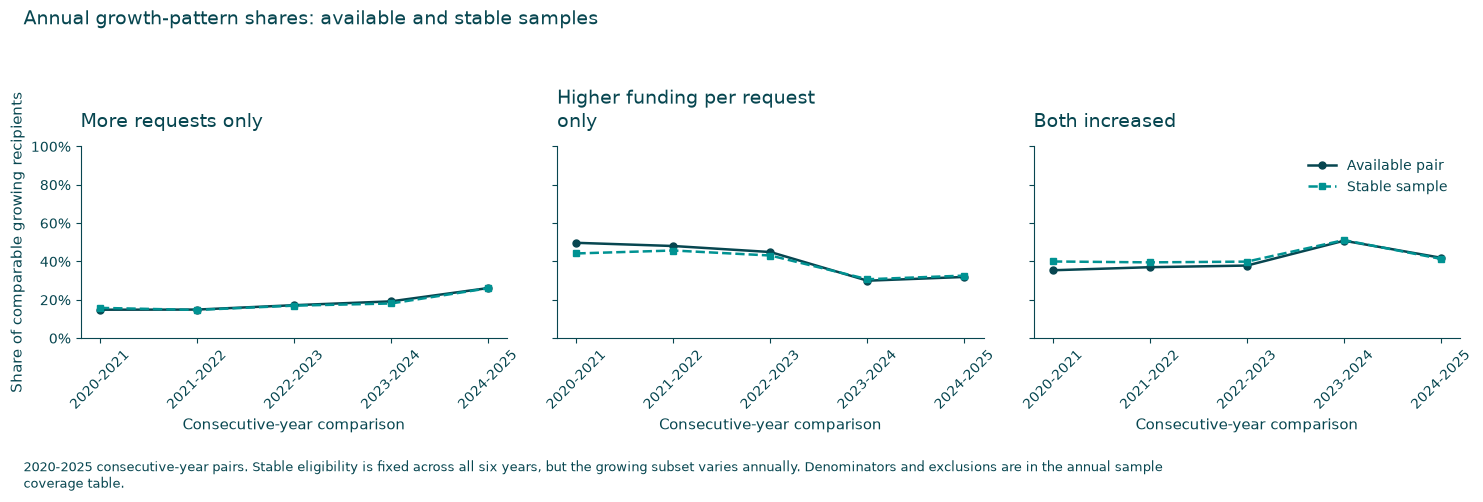

sample                                     Available pair  Stable sample  \
period    pattern                                                          
2020-2021 Both increased                         0.354254       0.400000   
          Higher funding per request only        0.497327       0.441941   
          More requests only                     0.148419       0.158059   
2021-2022 Both increased                         0.370192       0.395431   
          Higher funding per request only        0.480643       0.457267   
          More requests only                     0.149165       0.147302   
2022-2023 Both increased                         0.378749       0.399312   
          Higher funding per request only        0.449244       0.431087   
          More requests only                     0.172007       0.169601   
2023-2024 Both increased                         0.508260       0.511691   
          Higher funding per request only        0.299737       0.307390   
          More requests only                     0.192004       0.180918   
2024-2025 Both increased                         0.419391       0.413416   
          Higher funding per request only        0.319391       0.326404   
          More requests only                     0.261219       0.260180   

sample                                     stable_minus_available_pp  
period    pattern                                                     
2020-2021 Both increased                                    4.574616  
          Higher funding per request only                  -5.538543  
          More requests only                                0.963927  
2021-2022 Both increased                                    2.523896  
          Higher funding per request only                  -2.337607  
          More requests only                               -0.186289  
2022-2023 Both increased                                    2.056284  
          Higher funding per request only                  -1.815696  
          More requests only                               -0.240588  
2023-2024 Both increased                                    0.343190  
          Higher funding per request only                   0.765369  
          More requests only                               -1.108559  
2024-2025 Both increased                                   -0.597438  
          Higher funding per request only                   0.701319  
          More requests only                               -0.103881

In [30]:
from chart_style import finish_chart, growth_boxplot, contrast_text


fig, axes = plt.subplots(1, len(GROWTH_PATTERNS), figsize=(15, 5), sharey=True)
for ax, pattern in zip(axes, GROWTH_PATTERNS):
    chart = annual_sample_shares.xs(pattern, level="pattern")
    for sample, color in [("Available pair", CHART_COLORS["primary"]),
                          ("Stable sample", CHART_COLORS["secondary"])]:
        ax.plot(chart.index, chart[sample], marker="o" if sample == "Available pair" else "s", linestyle="-" if sample == "Available pair" else "--", color=color, label=sample)
    ax.set_title(pattern, fontsize=10)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.0%}"))
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel("Consecutive-year comparison")
axes[0].set_ylabel("Share of comparable growing recipients")
axes[-1].legend()
fig.suptitle("Annual growth-pattern shares: available and stable samples", x=.02, ha="left", fontsize=14)

finish_chart(plt.gcf(), '2020-2025 consecutive-year pairs. Stable eligibility is fixed across all six years, but the growing subset varies annually. Denominators and exclusions are in the annual sample coverage table.')

display(annual_sample_shares)



### Reading these views together

The population table accounts for the change in recorded funding totals. Pattern tables distinguish frequency from euro scale within comparable recipients. The stable-sample view checks whether annual pattern shares depend on which recipients can be compared.

The amounts, recipient counts and availability tables provide complementary evidence for interpreting the results. A frequent pattern need not contribute the most euros, and a stable overall mix does not mean each recipient followed the same pattern each year. Missing observations do not establish zero funding, organizational entry or closure.

## Appendix: shorter observation histories

The exported report keeps observed-period changes separate from fixed 2020-2025 comparisons. Durations differ, and one observed year is insufficient for growth. A compound annual rate is a constant-rate equivalent, not a record of the actual year-by-year path.

In [31]:
render_short_histories(period_summary, START_YEAR, END_YEAR, output_path=PROJECT_ROOT / "outputs" / "heatmaps" / "07_short_histories.html", preview_rows=30)

Recipient,First year,Last year,Observed years,Elapsed years,Observed-period growth,Annualized observed growth,History status
Lietuvos žemės ūkio bendrovių asociacija,2020,2023,4,3,177.3%,40.5%,Available
Asociacija LATGA,2022,2025,4,3,3475.5%,229.4%,Available
"Viešoji įstaiga ""Vilniaus verslo konsultacinis centras""",2020,2021,2,1,75.9%,75.9%,Available
Viešoji įstaiga Thomo Manno kultūros centras,2020,2022,3,2,-79.8%,-55.0%,Available
Viešoji įstaiga LIETUVOS INOVACIJŲ CENTRAS,2020,2023,4,3,15.3%,4.9%,Available
"Viešoji įstaiga ""Humana People to People Baltic""",2020,2020,1,0,Unavailable,Unavailable,Insufficient history
Janinos Monkutės Marks labdaros ir paramos fondas,2020,2024,5,4,-85.2%,-37.9%,Available
VIEŠOJI ĮSTAIGA BALTIJOS ŠALIŲ STRATEGINIO VYSTYMO INSTITUTAS,2020,2023,4,3,98.0%,25.6%,Available
KULTŪROS VYSTYMO IR ŠVIETIMO VIEŠOJI ĮSTAIGA,2020,2024,5,4,49.6%,10.6%,Available
"Viešoji įstaiga ""FURNITEST""",2020,2023,4,3,-85.2%,-47.1%,Available


## Reading the results together

Each comparison has a defined period and valid sample. Pattern frequency and the corresponding euro change describe different aspects of growth. Age, legal form and municipality comparisons describe selected groups; explaining causes would require a different study design.

[Previous notebook](06_top_1_newcomers_vs_returning.ipynb) | [Reading guide](../README.md#reading-order)